<h1><center>Shor's algorithm</center></h1>
<center>- Maxime Hantute -</center>

This notebook walks through the blocks of Shor's algorithm, from single-bit addition up to factoring 15 and 21. Each section explains a block, runs it on a simulator so you can change the inputs, and draws its circuit.

The arithmetic follows V. Vedral, A. Barenco and A. Ekert, *Quantum networks for elementary arithmetic operations*, Phys. Rev. A **54**, 147 (1996), and is written with X, CNOT and Toffoli gates only. Registers are little-endian (qubit 0 is the least significant bit), like everywhere in Qiskit.

In [1]:
from math import gcd

from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

from shor_qiskit import (adder, adder_mod, bit_sum, carry, ctrl_mult_mod, factor,
                         find_order, inverse_qft, mod_exp, order_finding_circuit, qft)

simulator = AerSimulator(method="matrix_product_state")


def load(qc, register, value):
    """Prepare |value> on a register in |0...0> (little-endian)."""
    for i, qubit in enumerate(register):
        if (value >> i) & 1:
            qc.x(qubit)


def measure(qc, *registers):
    """Run a classical-reversible circuit once and read each register as an integer."""
    qc = qc.copy()
    outputs = []
    for register in registers:
        bits = ClassicalRegister(len(register))
        qc.add_register(bits)
        qc.measure(register, bits)
        outputs.append(bits)
    counts = simulator.run(transpile(qc, simulator), shots=1).result().get_counts()
    words = next(iter(counts)).split()[::-1]  # Qiskit lists the last register first
    return [int(word, 2) for word in words]


def draw(qc):
    return qc.draw(output="mpl", fold=-1, scale=0.6)

## Sum
The SUM block computes the sum bit of a one-bit addition, $b \leftarrow a \oplus b \oplus c$, where $c$ is the incoming carry. It uses two CNOTs and is its own inverse.

expected sum bit 0, got 0


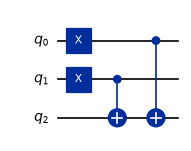

In [2]:
# Modify here
c_in, a, b = 1, 1, 0

reg = QuantumRegister(3, "q")  # q0 = carry in, q1 = a, q2 = b
qc = QuantumCircuit(reg)
load(qc, reg, c_in | a << 1 | b << 2)
bit_sum(qc, reg[0], reg[1], reg[2])
print(f"expected sum bit {(a + b + c_in) % 2}, got {measure(qc, reg[2:])[0]}")
draw(qc)

## Carry
The CARRY block computes the outgoing carry $c_{out} \leftarrow c_{out} \oplus \mathrm{maj}(c_{in}, a, b)$ with two Toffolis. As a side effect it leaves $b \oplus a$ in $b$; the SUM block later completes it to the full sum bit, and the adder runs CARRY backwards to restore the carries to 0.

carry out: expected 1, got 1;  b: expected a xor b = 1, got 1


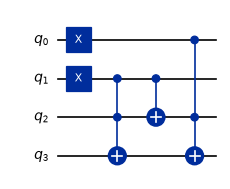

In [3]:
# Modify here
c_in, a, b = 1, 1, 0

reg = QuantumRegister(4, "q")  # q0 = carry in, q1 = a, q2 = b, q3 = carry out
qc = QuantumCircuit(reg)
load(qc, reg, c_in | a << 1 | b << 2)
carry(qc, reg[0], reg[1], reg[2], reg[3])
b_out, c_out = measure(qc, reg[2:3], reg[3:4])
print(f"carry out: expected {int(a + b + c_in >= 2)}, got {c_out};  b: expected a xor b = {a ^ b}, got {b_out}")
draw(qc)

## Adder
The ripple-carry adder chains CARRY blocks from the lowest bit to the highest, writes the top sum bit, then walks back down undoing each CARRY and applying SUM. The result $a+b$ is written into $b$, which has one extra qubit for the final carry. Running the same network backwards ($\texttt{inverse=True}$) subtracts.
<img src="files/adder.PNG" />

5 + 7: expected 12, got 12


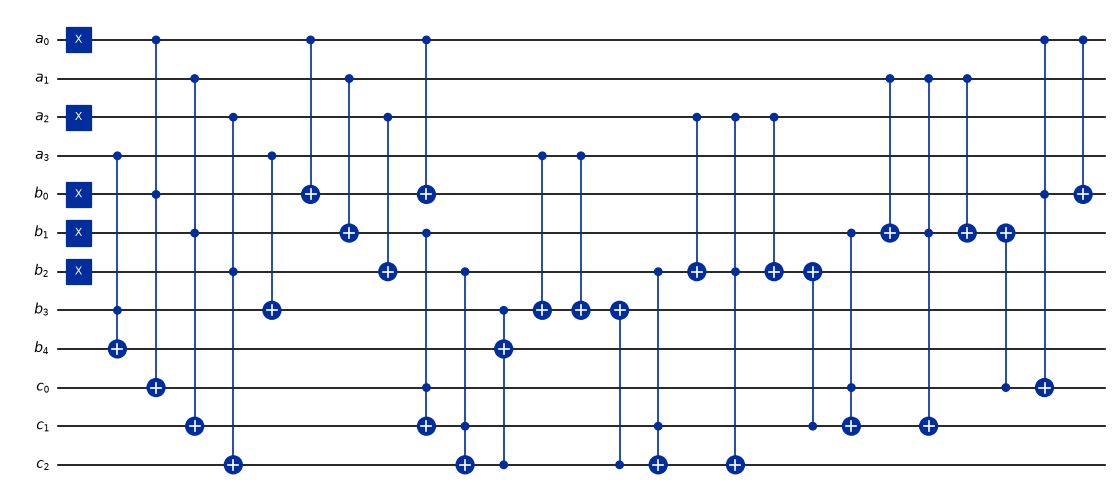

In [4]:
# Modify here
number1, number2, n = 5, 7, 4

a = QuantumRegister(n, "a")
b = QuantumRegister(n + 1, "b")
carries = QuantumRegister(n - 1, "c")
qc = QuantumCircuit(a, b, carries)
load(qc, a, number1)
load(qc, b, number2)
adder(qc, a, b, carries)
print(f"{number1} + {number2}: expected {number1 + number2}, got {measure(qc, b)[0]}")
draw(qc)

## Modular adder
The modular adder computes $(a + b) \bmod N$ for $0 \le a, b < N$: add $a$, subtract $N$, use the sign bit to decide whether to add $N$ back, then subtract and re-add $a$ to reset that decision qubit to 0.

$N$ is a classical number, so it is not stored in a register: every 1 bit of $N$ becomes a gate (or a gate controlled on the decision qubit $t$), and every 0 bit is dropped.
<img src="files/adder_mod.PNG" />

(6 + 3) mod 7: expected 2, got 2


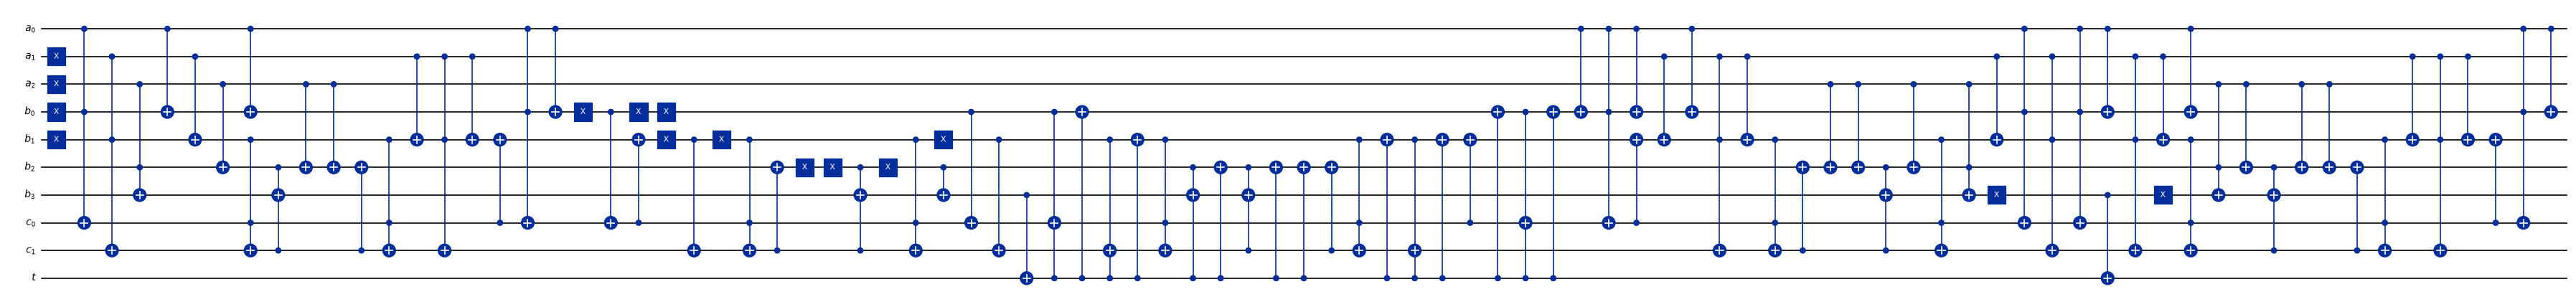

In [5]:
# Modify here (needs 0 <= number1, number2 < modulo < 2**n)
number1, number2, modulo, n = 6, 3, 7, 3

a = QuantumRegister(n, "a")
b = QuantumRegister(n + 1, "b")
carries = QuantumRegister(n - 1, "c")
t = QuantumRegister(1, "t")
qc = QuantumCircuit(a, b, carries, t)
load(qc, a, number1)
load(qc, b, number2)
adder_mod(qc, a, b, modulo, carries, t[0])
print(f"({number1} + {number2}) mod {modulo}: expected {(number1 + number2) % modulo}, got {measure(qc, b)[0]}")
draw(qc)

## Controlled modular multiplication and modular exponentiation
The controlled multiplier writes $a\cdot x \bmod N$ into an empty register when the control is 1, using $a x = \sum_k x_k (a 2^k \bmod N)$: for each bit $x_k$, the precomputed constant $a 2^k \bmod N$ is added with the modular adder. If the control is 0 it copies $x$ instead.

The modular exponentiation chains these multipliers, one per exponent bit $e_i$, with the constants $a^{2^i} \bmod N$. After each multiplication the two registers swap roles, and the old one is cleared by running the multiplier backwards with the modular inverse $a^{-2^i} \bmod N$.
<img src="files/mult_mod_and_exp_mod.PNG" />

In [6]:
# Modify here
base, modulo, ctrl_value, x_value = 7, 15, 1, 4

n = modulo.bit_length()
ctrl = QuantumRegister(1, "ctrl")
x = QuantumRegister(n, "x")
z = QuantumRegister(n + 1, "z")
carries = QuantumRegister(n - 1, "c")
anc = QuantumRegister(2, "anc")
qc = QuantumCircuit(ctrl, x, z, carries, anc)
load(qc, ctrl, ctrl_value)
load(qc, x, x_value)
ctrl_mult_mod(qc, ctrl[0], x, z, base, modulo, carries, anc[0], anc[1])
expected = base * x_value % modulo if ctrl_value else x_value
print(f"ctrl = {ctrl_value}: expected {expected}, got {measure(qc, z)[0]}  ({qc.size()} gates)")

ctrl = 1: expected 13, got 13  (515 gates)


In [7]:
# Modify here
base, modulo, n_exponent = 7, 15, 4

n = modulo.bit_length()
print("e  a^e mod N  circuit")
for e_value in range(2**n_exponent):
    e = QuantumRegister(n_exponent, "e")
    x = QuantumRegister(n + 1, "x")
    z = QuantumRegister(n + 1, "z")
    carries = QuantumRegister(n - 1, "c")
    anc = QuantumRegister(2, "anc")
    qc = QuantumCircuit(e, x, z, carries, anc)
    load(qc, e, e_value)
    result = mod_exp(qc, e, x, z, base, modulo, carries, anc[0], anc[1])
    print(f"{e_value:<2} {pow(base, e_value, modulo):<10} {measure(qc, result)[0]}")

e  a^e mod N  circuit


0  1          1


1  7          7


2  4          4


3  13         13


...

11 13         13


12 1          1


13 7          7


14 4          4


15 13         13


## Quantum Fourier transform
The inverse QFT turns the periodic pattern left in the counting register into peaks near multiples of $2^t/r$. It is written out with Hadamard, controlled-phase and SWAP gates.

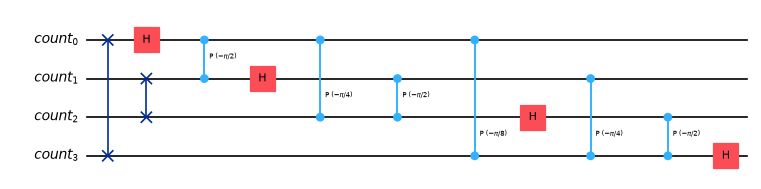

In [8]:
reg = QuantumRegister(4, "count")
qc = QuantumCircuit(reg)
inverse_qft(qc, reg)
draw(qc)

## Order finding
The full circuit: Hadamards on a counting register of $2n$ qubits, the modular exponentiation, the inverse QFT and a measurement. For $a = 7$, $N = 15$ the order is $r = 4$, so the outcomes are $0, 64, 128, 192$ out of $2^8 = 256$; a continued-fraction expansion of $y/2^8$ recovers $r$.

The simulator is Aer's matrix-product-state method, which handles this 23-qubit circuit in under a second.

23 qubits, 1881 gates
order of 7 mod 15: 4


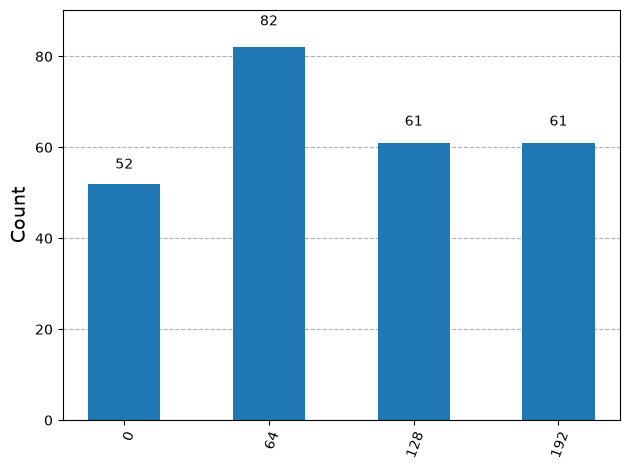

In [9]:
# Modify here
base, modulo = 7, 15

qc = order_finding_circuit(base, modulo)
print(f"{qc.num_qubits} qubits, {qc.size()} gates")
r, counts = find_order(base, modulo, shots=256, seed=7)
print(f"order of {base} mod {modulo}: {r}")
plot_histogram({int(k, 2): v for k, v in counts.items()})

## Factoring
`factor` adds the classical steps around order finding: reject even numbers, primes and perfect powers, pick a random base $a$, find its order $r$, and if $r$ is even with $a^{r/2} \not\equiv -1 \pmod N$, return $\gcd(a^{r/2} \pm 1, N)$. `allow_lucky_gcd=False` forces the quantum part to run even when the random $a$ already shares a factor with $N$.

In [10]:
for N in (15, 21):
    result = factor(N, seed=3, allow_lucky_gcd=False)
    print(f"{N} = {result.factors[0]} x {result.factors[1]}  (a = {result.a}, order r = {result.order}, method: {result.method})")

15 = 3 x 5  (a = 11, order r = 2, method: order finding)


21 = 3 x 7  (a = 19, order r = 6, method: order finding)
